### Import Required Libraries

This notebook uses standard Python libraries for data manipulation, visualization, and time series analysis. Warnings related to data types are suppressed to keep outputs clean and focused.


In [1]:
import warnings
import pandas as pd
warnings.filterwarnings("ignore", category=pd.errors.DtypeWarning)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller



### Dataset Loading

The Rossmann dataset consists of three files:
- **train.csv**: Historical daily sales data
- **test.csv**: Future dates for prediction
- **store.csv**: Store-level metadata

These datasets are loaded separately and later merged for analysis.


In [2]:
train_df=pd.read_csv("../data/train.csv")
train_df.head(5)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


### Dataset Description
- Store : Unique store identifier (storeID/storeName).
- DayOfWeek : Day of sale (1 = Monday, 2 = Tuesday … 7 = Sunday).
- Date : Calendar date of the sale.
- Sales : Target variable representing daily revenue.
- Customers : Number of customers visiting the store that day.
- Open : Store status (1 = open, 0 = closed).
- Promo : Promotion flag (1 = running promotion, 0 = no promotion).
- StateHoliday : Holiday type (0 = none, a = public holiday, b = Easter, c = Christmas).
- SchoolHoliday : School closure indicator (1 = school holiday, 0 = no school holiday).


In [3]:
test_df=pd.read_csv("../data/test.csv")
test_df.head()

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0


In [4]:
store_df=pd.read_csv("../data/store.csv")
store_df.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


- Store : Unique identifier for each store.
- StoreType : Category of store (e.g., a, b, c, d) indicating format/size.
- Assortment : Level of product variety offered (a = basic, b = extra, c = extended).
- CompetitionDistance : Distance in meters to the nearest competitor store.
- CompetitionOpenSinceMonth : Month when the nearest competitor opened.
- CompetitionOpenSinceYear : Year when the nearest competitor opened.
- Promo2 : Flag for whether the store is participating in a continuous promotion (0 = no, 1 = yes).
- Promo2SinceWeek : Calendar week when Promo2 started for the store.
- Promo2SinceYear : Year when Promo2 started for the store.
- PromoInterval : Months when Promo2 is active (e.g., Jan, Apr, Jul, Oct).


### Dataset Dimensions

The shape of each dataset is examined to understand data volume and structure before merging.


In [5]:
print(f'Shape of the train data is {train_df.shape}\n{'-----'*10}\nShape of the test data is {test_df.shape}\n{'-----'*10}\nShape of the Store dataset is {store_df.shape}')

Shape of the train data is (1017209, 9)
--------------------------------------------------
Shape of the test data is (41088, 8)
--------------------------------------------------
Shape of the Store dataset is (1115, 10)


### Data Merging

Transactional sales data is merged with store-level metadata using the `Store` identifier.  
This enriches the dataset with contextual features such as store type and assortment, which are useful for analysis and forecasting.


In [6]:
df = train_df.merge(store_df, on='Store', how='left')


In [7]:
df.shape

(1017209, 18)

In [8]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   Store                      1017209 non-null  int64  
 1   DayOfWeek                  1017209 non-null  int64  
 2   Date                       1017209 non-null  str    
 3   Sales                      1017209 non-null  int64  
 4   Customers                  1017209 non-null  int64  
 5   Open                       1017209 non-null  int64  
 6   Promo                      1017209 non-null  int64  
 7   StateHoliday               1017209 non-null  object 
 8   SchoolHoliday              1017209 non-null  int64  
 9   StoreType                  1017209 non-null  str    
 10  Assortment                 1017209 non-null  str    
 11  CompetitionDistance        1014567 non-null  float64
 12  CompetitionOpenSinceMonth  693861 non-null   float64
 13  CompetitionOpenSinceYea

### Date Processing

The `Date` column is converted to datetime format and the data is sorted chronologically.  
This step is essential in time series analysis to prevent data leakage and ensure correct temporal ordering.


In [10]:
df['Date'] = pd.to_datetime(df['Date'])
df.sort_values('Date', inplace=True)


Time series data must be sorted chronologically to prevent data leakage

In [11]:
df[['Date','Sales']]

,Date,Sales
1017208,2013-01-01,0
1016473,2013-01-01,0
1016472,2013-01-01,0
1016471,2013-01-01,0
1016470,2013-01-01,0
...,...,...
745,2015-07-31,9082
746,2015-07-31,10708
747,2015-07-31,7481
741,2015-07-31,10460


### Store Selection

The dataset contains sales data for 1,115 stores.  
To build a clean and interpretable forecasting pipeline, the analysis focuses on a single representative store (Store 1).


In [12]:
store_id = 1
store = df[df['Store'] == store_id]


In [13]:
store.shape

(942, 18)

In [14]:
store.describe().T

,count,mean,min,25%,50%,75%,max,std
Store,942.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
DayOfWeek,942.0,3.997877,1.0,2.0,4.0,6.0,7.0,1.998404
Date,942,2014-04-16 12:00:00,2013-01-01 00:00:00,2013-08-24 06:00:00,2014-04-16 12:00:00,2014-12-07 18:00:00,2015-07-31 00:00:00,NaN
Sales,942.0,3945.704883,0.0,3588.25,4373.5,5220.0,9528.0,2015.41784
Customers,942.0,467.646497,0.0,463.0,529.0,598.75,1130.0,228.93085
Open,942.0,0.829087,0.0,1.0,1.0,1.0,1.0,0.376633
Promo,942.0,0.382166,0.0,0.0,0.0,1.0,1.0,0.486175
SchoolHoliday,942.0,0.204883,0.0,0.0,0.0,0.0,1.0,0.403831
CompetitionDistance,942.0,1270.0,1270.0,1270.0,1270.0,1270.0,1270.0,0.0
CompetitionOpenSinceMonth,942.0,9.0,9.0,9.0,9.0,9.0,9.0,0.0


In [15]:
store.Open.value_counts()

Open
1    781
0    161
Name: count, dtype: int64

Zero sales during store closures are valid business signals, not missing values.

In [16]:
store.head(10)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
1016095,1,2,2013-01-01,0,0,0,0,a,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1014980,1,3,2013-01-02,5530,668,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1013865,1,4,2013-01-03,4327,578,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1012750,1,5,2013-01-04,4486,619,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1011635,1,6,2013-01-05,4997,635,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1010520,1,7,2013-01-06,0,0,0,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1009405,1,1,2013-01-07,7176,785,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1008290,1,2,2013-01-08,5580,654,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1007175,1,3,2013-01-09,5471,626,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1006060,1,4,2013-01-10,4892,615,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN


### Daily Sales Visualization

The daily sales time series shows strong weekly seasonality, characterized by repeated zero-sales days corresponding to store closures (typically Sundays).

Between open days, sales remain relatively stable with moderate fluctuations. Occasional spikes in sales may be influenced by promotions or holiday periods.


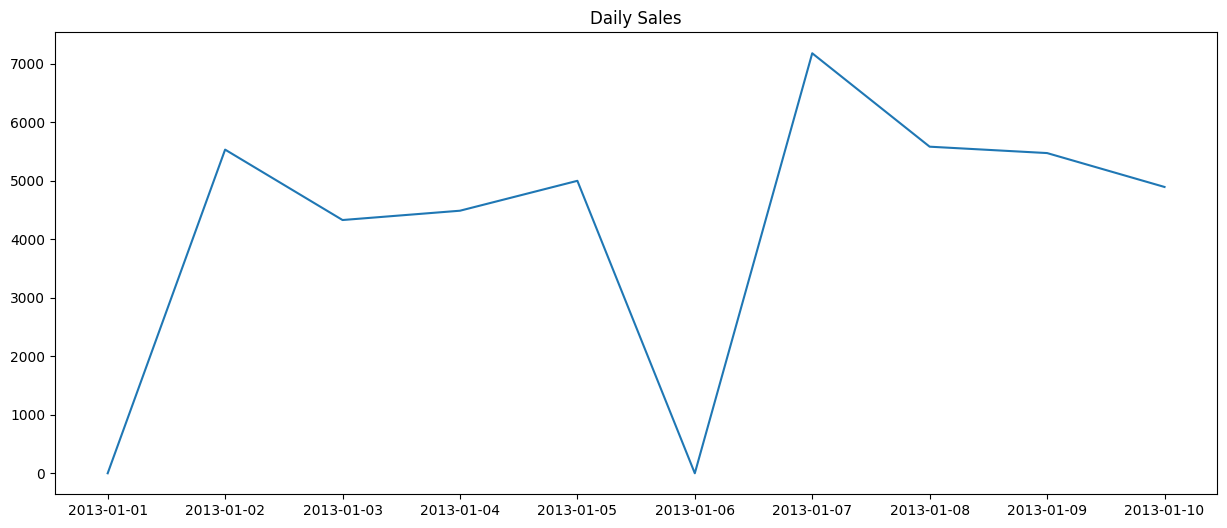

In [17]:
plt.figure(figsize=(15,6))
plt.plot(store.Date[:10], store.Sales[:10])
plt.title("Daily Sales")
plt.show()

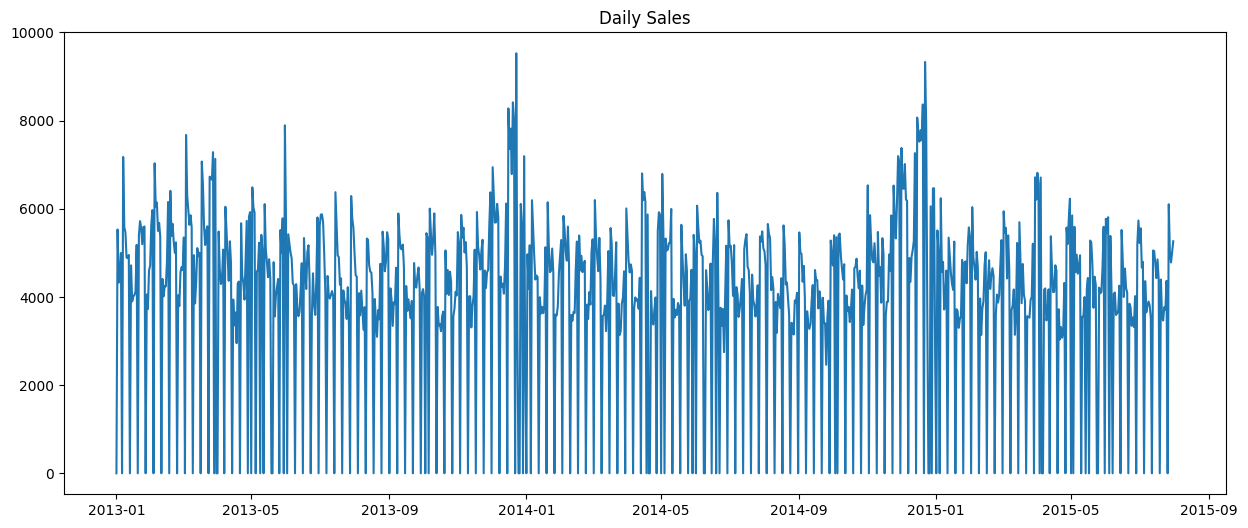

In [18]:
plt.figure(figsize=(15,6))
plt.plot(store.Date, store.Sales)
plt.title("Daily Sales")
plt.show()

### Seasonal Decomposition

Seasonal decomposition confirms a strong weekly seasonal pattern driven by store closures.  
The trend component remains relatively stable, indicating consistent long-term demand.

Residual components capture irregular fluctuations and sudden spikes, which may correspond to promotions or anomalous sales behavior. This validates the suitability of the data for forecasting and anomaly detection.


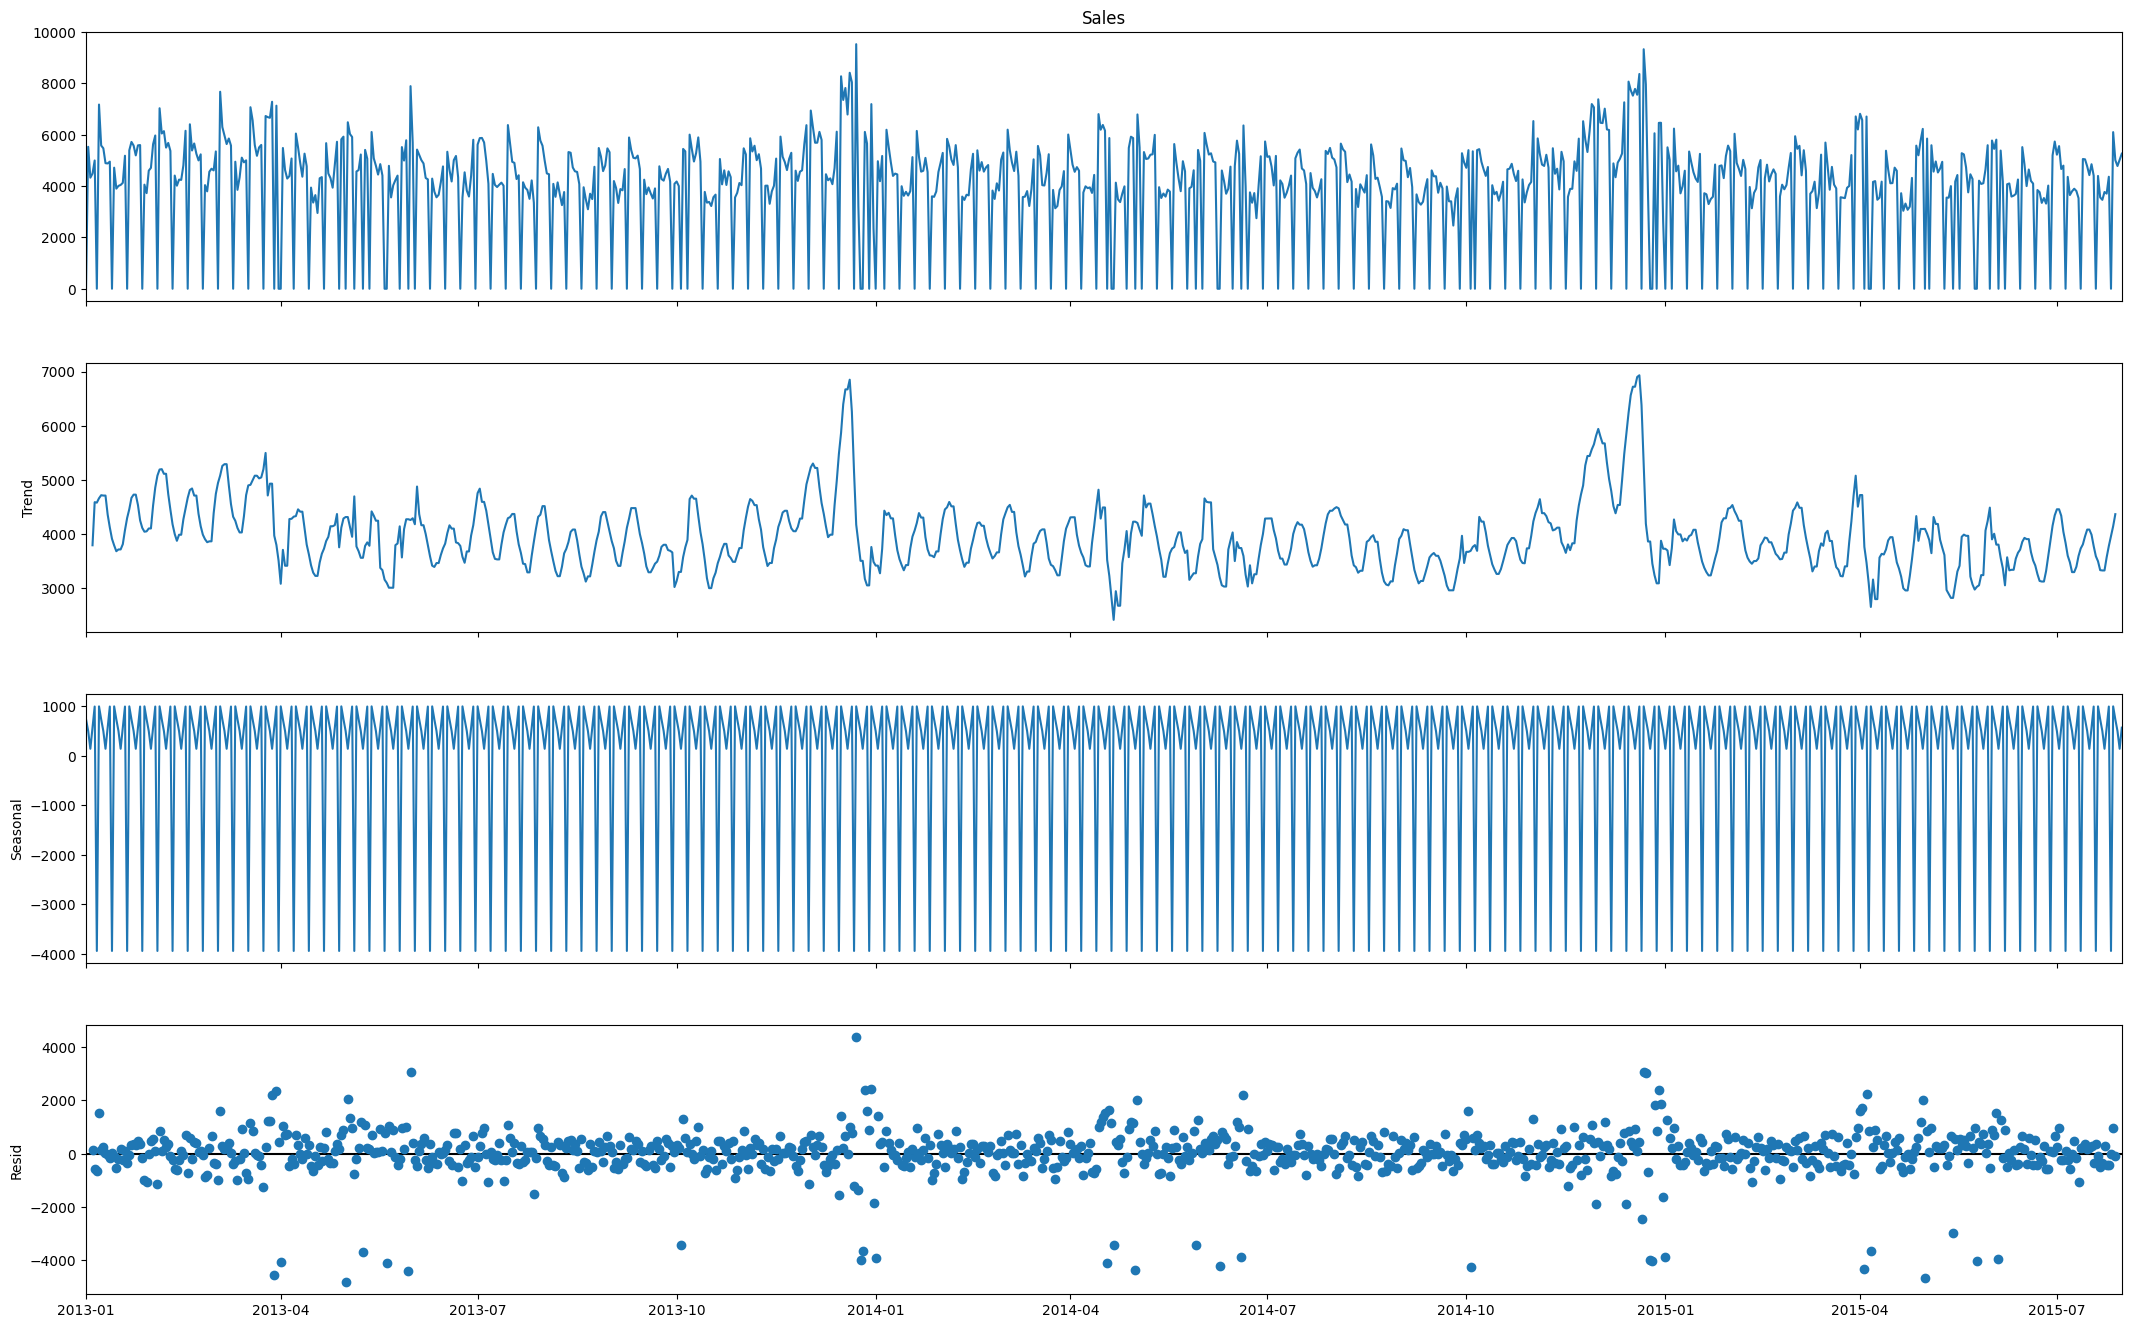

In [19]:
result = seasonal_decompose(store.set_index('Date')['Sales'], model='additive', period=7)
fig=result.plot()
fig.set_size_inches(25, 15)
plt.show()


### Impact of Promotions and Weekly Patterns

Sales during promotional periods are higher on average compared to non-promotional days, confirming the business impact of promotions.

Day-wise average sales further reinforce the weekly pattern observed in the time series, with lower sales on store closure days.


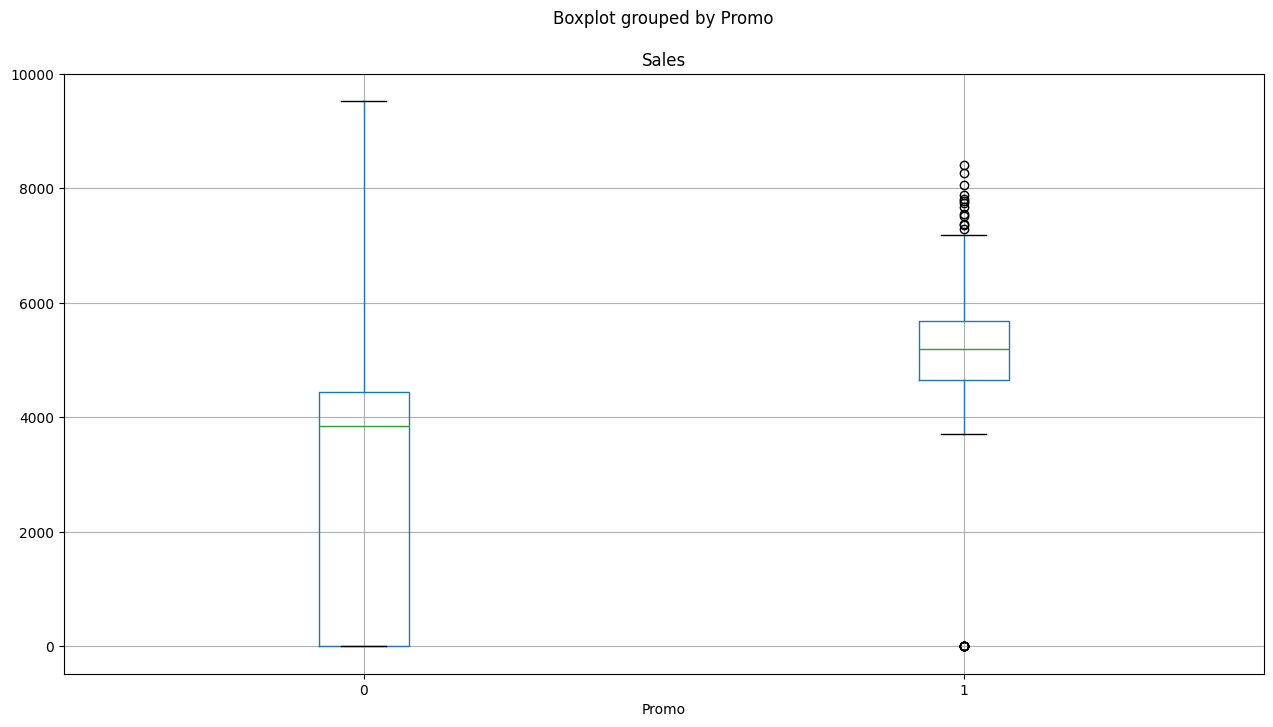

In [20]:

store.groupby('Promo')['Sales'].mean()
store.boxplot(column='Sales', by='Promo', figsize=(15,8))
plt.show()


In [21]:
store.groupby(store['Date'].dt.day_name())['Sales'].mean()


Date
Friday       4516.414815
Monday       4946.119403
Saturday     4942.970149
Sunday          0.000000
Thursday     4094.607407
Tuesday      4650.918519
Wednesday    4454.474074
Name: Sales, dtype: float64

### Forecasting Data Preparation

The dataset is reformatted to match Prophet’s required structure:
- `ds`: Date
- `y`: Target variable (Sales)

This clean time series will be used for forecasting in the next stage.


The known-in-advance calendar columns (`Open`, `Promo`, `StateHoliday`, `SchoolHoliday`) are kept next to `y` so they can be used as Prophet regressors in the forecasting notebook.

In [22]:
store = store.copy()
# StateHoliday mixes 0 / 'a' / 'b' / 'c' strings; collapse to a 0/1 flag for use as a regressor
store['StateHoliday'] = (store['StateHoliday'].astype(str) != '0').astype(int)

ts_df = store[['Date', 'Sales', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']].rename(
    columns={'Date': 'ds', 'Sales': 'y'}
)

In [23]:
ts_df.set_index('ds', inplace=True)
ts_df.head()


,y,Open,Promo,StateHoliday,SchoolHoliday
ds,,,,,
2013-01-01,0,0,0,1,1
2013-01-02,5530,1,0,0,1
2013-01-03,4327,1,0,0,1
2013-01-04,4486,1,0,0,1
2013-01-05,4997,1,0,0,1


In [24]:
ts_df.reset_index().to_csv("../data/processed_store1.csv", index=False)


In [25]:
def adfuller_test(sales):
    result=adfuller(sales)
    labels=["ADF test statistic", "p-value", "No. of lags used", "Number of observation used"]
    for res, label in zip(result, labels):
        print(f"{label} : {str(res)}")
    if result[1]<=0.05:
        print("Stationary")
    else:
        print("Not-Stationary")

In [26]:
adfuller_test(ts_df.y)

ADF test statistic : -4.368104368168492
p-value : 0.00033788346141425287
No. of lags used : 21
Number of observation used : 920
Stationary


**Reading the ADF result.** p = 0.0003 rejects the unit-root null, so the series is treated as stationary. The strong 7-day cycle and the structural zeros are still present, so stationarity alone does not make a non-seasonal model adequate; the forecasting notebook uses seasonal terms and calendar regressors for that reason.